# Stage 6: Monte Carlo of played games

Research question RQ3: how much of a game result comes from the quality of the shots a team created, and how much
from luck in making them?

Idea: keep everything that happened in a game (who shot, from where, in which situation, how many free throws were
made) and redraw only the **results of the field goal attempts**. Each shot is made with the out-of-sample
probability p of the main model (`gbm_w2_ctx`). One simulation gives a final score; 10,000 simulations give the
distribution of scores the game "could have had" with the same shots.

Per game this gives:
- **P(win)**: the share of simulations the home team wins (a tie counts 1/2),
- **luck percentile**: where the real margin lies in the simulated distribution (0.5 = exactly as expected, 0.95 =
  the home team made far more than expected).

Decisions:
- free throws are taken as **observed (FTM)**, so luck refers to field goals only; drawing free throws is a sensitivity
  check (section 7);
- shots are grouped into **chains** (a shot and the putbacks after offensive rebounds); section 1 shows why the naive
  model with independent shots fails;
- p is the probability for an **average** shooter, so "luck" here still contains the shot making of the players.
  Section 6 repeats the analysis with p adjusted by each player's shot making from the previous season (Stage 5);
- seasons 2015-16 to 2024-25, the hold-out 2025-26 once at the end (section 9).

## 0. Setup

In [1]:
%load_ext autoreload
# re-import src/xpts after every change, no kernel restart needed
%autoreload 2

import glob
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from xpts.players import load_player_shots, player_table, season_estimates
from xpts.simulation import load_games, margin_dist, putback_params, run_games, simulate_team, team_pmf

FIG_DIR = Path("../reports/figures")
P = "../data/processed/"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
N_SIMS = 10_000

shots, games, n_bad = load_games(P + "oos_predictions.parquet", P + "shots_features.parquet", P + "shots_context.parquet",
                                 "../data/raw/games")
print(f"{len(games):,} games, {len(shots):,} shots; dropped {n_bad} games whose box score points are not reproduced")
print(f"home win share {games['home_win'].mean():.3f}, mean margin {games['margin'].mean():+.2f}")

11,881 games, 2,083,779 shots; dropped 93 games whose box score points are not reproduced
home win share 0.565, mean margin +2.19


## 1. Data check and why shots must be grouped into chains

`load_games` joins the shots (with p) to the box scores of `leaguegamelog`. For every team-game, field goal points
from the shot data plus the real FTM must equal the official points; otherwise shots are missing and the game cannot be
simulated honestly. Only 93 games (0.8%, almost all in 2015-16 and 2016-17) fail this check and are dropped.

**The naive model** draws every shot independently with the real number of shots. Its problem: the number of shots is
not independent of the results. A team that misses a lot gets more offensive rebounds and therefore more shots, and
each extra shot adds expected points. The first version of this notebook showed exactly this (correlations below).

**Chains.** A shot that follows an offensive rebound after a miss of the same team in the same period (play-by-play
`prev_event`) belongs to the chain of that miss. In a simulation a chain scores the value of its first made shot and
stops; if the last shot of a chain was made in reality but misses in the simulation, the team gets an offensive rebound
with the league rate ρ of the **previous season** and a generic putback worth 2 points with probability p_pb
(`putback_params`, at most 3 extra attempts).

In [2]:
pp = putback_params(P + "shots_features.parquet", P + "shots_context.parquet")
params = pp.shift(1)                      # previous season's values; 2015-16 uses 2014-15
params.loc["2015-16"] = pp.loc["2014-15"]
display(pp.round(4))
print(f"putbacks (chain continuations): {shots['cont'].mean():.1%} of shots; chains with 2+ shots: "
      f"{(shots.groupby('chain').size() > 1).mean():.1%}")
display(games.groupby("SEASON").agg(games=("GAME_ID", "size"), home_win=("home_win", "mean"),
                                    pts_home=("PTS_home", "mean"), pts_away=("PTS_away", "mean")).round(3))

,rho,p_pb,share_cont
SEASON,,,
2014-15,0.2028,0.5295,0.1118
2015-16,0.1951,0.5318,0.1069
2016-17,0.1904,0.5476,0.1034
2017-18,0.1835,0.5552,0.0990
2018-19,0.1915,0.5552,0.1033
2019-20,0.1812,0.5580,0.0978
2020-21,0.1806,0.5664,0.0964
2021-22,0.1866,0.5606,0.1006
2022-23,0.1928,0.5723,0.1011


putbacks (chain continuations): 10.2% of shots; chains with 2+ shots: 10.1%


,games,home_win,pts_home,pts_away
SEASON,,,,
2015-16,1193,0.588,104.073,101.416
2016-17,1174,0.584,107.138,103.990
2017-18,1230,0.579,107.386,105.280
2018-19,1230,0.593,112.571,109.846
2019-20,1059,0.551,112.863,110.733
2020-21,1080,0.544,112.563,111.619
2021-22,1230,0.544,111.477,109.754
2022-23,1230,0.580,115.936,113.436
2023-24,1230,0.543,115.285,113.138


## 2. One game in detail

The simulated margin of one game, the exact distribution and the real margin. The exact distribution of a team's points
is built chain by chain (`team_pmf`: a chain gives v_1 with p_1, otherwise continues with the next shot) and the
chains are combined by convolution; the margin distribution is the convolution of the two teams (`margin_dist`).

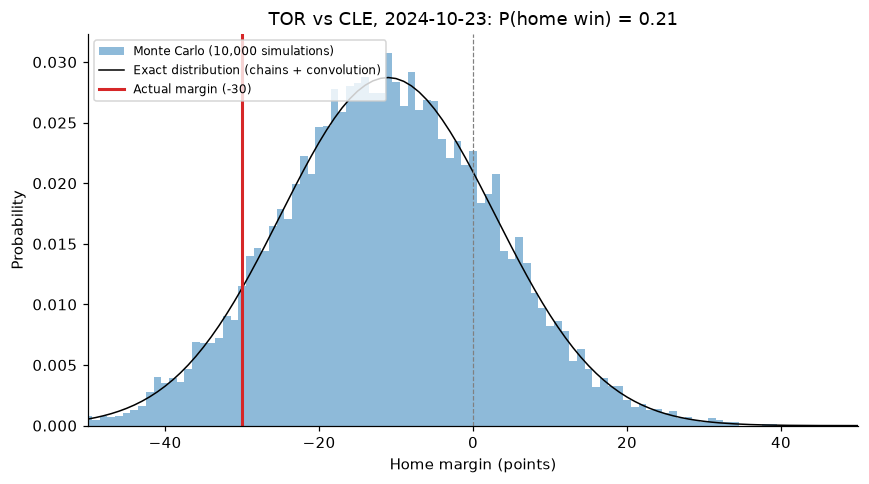

expected margin -11.0, sd 13.9; P(win) MC 0.2159, exact 0.2132; luck percentile 0.086


In [3]:
def team_arrays(gs, side, p_col="p"):
    t = gs[gs["side"] == side]
    return t[p_col].to_numpy(), t["shot_value"].to_numpy(), t["chain"].to_numpy(), t["chain_last_made"].to_numpy()

g_idx = games.set_index("GAME_ID")
gid = g_idx[(g_idx["SEASON"] == "2024-25") & (g_idx["home_win"] == 0)].index[4]
row = g_idx.loc[gid]
gs = shots[shots["GAME_ID"] == gid]
rho, p_pb = params.loc[row["SEASON"], "rho"], params.loc[row["SEASON"], "p_pb"]
ft = int(row["FTM_home"] - row["FTM_away"])
th, ta = team_arrays(gs, "home"), team_arrays(gs, "away")
rng = np.random.default_rng(1)
m = simulate_team(*th, rng, N_SIMS, rho, p_pb) - simulate_team(*ta, rng, N_SIMS, rho, p_pb) + ft
x, d = margin_dist(team_pmf(*th, rho, p_pb), team_pmf(*ta, rho, p_pb), ft)
p_exact = d[x > 0].sum() + 0.5 * d[x == 0].sum()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(m, bins=np.arange(-50.5, 51.5, 1), density=True, color="tab:blue", alpha=0.5, label=f"Monte Carlo ({N_SIMS:,} simulations)")
ax.plot(x, d, color="black", lw=1, label="Exact distribution (chains + convolution)")
ax.axvline(row["margin"], color="tab:red", lw=2, label=f"Actual margin ({row['margin']:+d})")
ax.axvline(0, color="grey", lw=0.8, ls="--")
ax.set(xlim=(-50, 50), xlabel="Home margin (points)", ylabel="Probability",
       title=f"{row['TEAM_ABBREVIATION_home']} vs {row['TEAM_ABBREVIATION_away']}, {row['GAME_DATE']:%Y-%m-%d}: P(home win) = {p_exact:.2f}")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_example_game.pdf")
plt.show()
print(f"expected margin {np.sum(x * d):+.1f}, sd {m.std():.1f}; P(win) MC {(m > 0).mean() + 0.5 * (m == 0).mean():.4f}, exact {p_exact:.4f}; "
      f"luck percentile {d[x < row['margin']].sum() + 0.5 * d[x == row['margin']].sum():.3f}")

**Observations.**
- Example game: expected margin −11.0 points with sd 13.9, exact P(home win) 0.213, Monte Carlo 0.216 (difference within
  one standard error, 0.004). The home team lost by more than expected (luck percentile 0.09).
- The sd of a game margin due to field goal luck alone is about 14 points: with the same shots, the result of an NBA
  game can easily swing by ±25 points.

## 3. Quality of the simulation

1. **Monte Carlo error.** P(win) from N simulations has standard error √(P(1 − P)/N), at most 0.005 for N = 10,000.
2. **Convergence** in the example game: running estimate against N with the 95% band around the exact value.
3. **Antithetic variates**: half of the uniforms U are replaced by 1 − U. The two halves are negatively correlated, which
   can reduce the variance of the estimate at the same cost. Measured by repeating the estimate 100 times for 30 games.
4. **Normal approximation** N(mean, variance of the exact distribution), checked on all games in section 4.

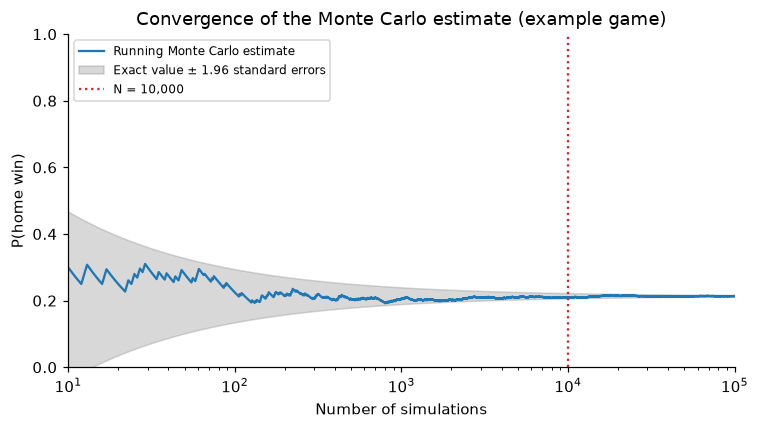

sd of P(win) over 100 repetitions, mean over 30 games: plain 0.00437, antithetic 0.00362; variance ratio 0.68


In [4]:
rng = np.random.default_rng(2)
m = simulate_team(*th, rng, 100_000, rho, p_pb) - simulate_team(*ta, rng, 100_000, rho, p_pb) + ft
w = (m > 0) + 0.5 * (m == 0)
n = np.arange(1, len(w) + 1)
se = np.sqrt(p_exact * (1 - p_exact) / n)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(n, np.cumsum(w) / n, color="tab:blue", label="Running Monte Carlo estimate")
ax.fill_between(n, p_exact - 1.96 * se, p_exact + 1.96 * se, color="grey", alpha=0.3, label="Exact value ± 1.96 standard errors")
ax.axvline(N_SIMS, color="tab:red", ls=":", label=f"N = {N_SIMS:,}")
ax.set(xscale="log", xlim=(10, 100_000), ylim=(0, 1), xlabel="Number of simulations", ylabel="P(home win)",
       title="Convergence of the Monte Carlo estimate (example game)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_convergence.pdf")
plt.show()

rows = []
for gid_ in games.sample(30, random_state=0)["GAME_ID"]:
    gs_ = shots[shots["GAME_ID"] == gid_]
    r_ = g_idx.loc[gid_]
    a_, b_ = team_arrays(gs_, "home"), team_arrays(gs_, "away")
    rh, pb = params.loc[r_["SEASON"], "rho"], params.loc[r_["SEASON"], "p_pb"]
    ft_ = int(r_["FTM_home"] - r_["FTM_away"])
    rng = np.random.default_rng(3)
    est = {False: [], True: []}
    for anti in (False, True):
        for _ in range(100):
            if anti:
                uh = rng.random((N_SIMS // 2, len(a_[0])), dtype=np.float32)
                ua = rng.random((N_SIMS // 2, len(b_[0])), dtype=np.float32)
                uh, ua = np.vstack([uh, 1 - uh]), np.vstack([ua, 1 - ua])
            else:
                uh = ua = None
            mm = simulate_team(*a_, rng, N_SIMS, rh, pb, uh) - simulate_team(*b_, rng, N_SIMS, rh, pb, ua) + ft_
            est[anti].append((mm > 0).mean() + 0.5 * (mm == 0).mean())
    rows.append({"sd_plain": np.std(est[False]), "sd_anti": np.std(est[True])})
anti = pd.DataFrame(rows)
print(f"sd of P(win) over 100 repetitions, mean over 30 games: plain {anti['sd_plain'].mean():.5f}, "
      f"antithetic {anti['sd_anti'].mean():.5f}; variance ratio {(anti['sd_anti'] ** 2).mean() / (anti['sd_plain'] ** 2).mean():.2f}")

**Observations.**
- The running estimate stays inside the ±1.96 SE band around the exact value; at N = 10,000 the standard error is
  about 0.004.
- Antithetic variates reduce the variance of P(win) by about a third (variance ratio 0.68; sd 0.0044 → 0.0036), which is
  equivalent to about 1.5 times as many simulations for free. The gain is modest because P(win) is a threshold (win /
  loss) of a sum of many shots. With the exact method available, the main runs use plain Monte Carlo.

## 4. All games: Monte Carlo, exact and normal; naive vs chains

`run_games` simulates every game (10,000 draws) and computes the exact and normal results. Results are saved to
`data/processed/game_simulations.parquet` for Stage 6b. The naive model (independent shots, fixed counts) is computed
exactly for comparison.

In [5]:
sim = run_games(shots, games, params, n_sims=N_SIMS, seed=0)
sim.to_parquet(P + "game_simulations.parquet")
naive = run_games(shots, games, params, chains=False, mc=False)
diff_mc = sim["p_win_mc"] - sim["p_win_exact"]
diff_n = sim["p_win_normal"] - sim["p_win_exact"]
print(f"MC - exact:     mean |diff| {diff_mc.abs().mean():.4f}, max {diff_mc.abs().max():.4f}, "
      f"share within 1.96 SE {(diff_mc.abs() <= 1.96 * np.sqrt(sim['p_win_exact'] * (1 - sim['p_win_exact']) / N_SIMS) + 1e-12).mean():.3f}")
print(f"normal - exact: mean |diff| {diff_n.abs().mean():.4f}, max {diff_n.abs().max():.4f}")
print(f"sd of the simulated margin: mean {sim['sd_margin'].mean():.2f} points (range {sim['sd_margin'].min():.1f}-{sim['sd_margin'].max():.1f})")

for name, s in [("naive", naive), ("chains", sim)]:
    c = s.assign(dFGA=s["FGA_home"] - s["FGA_away"], dOREB=s["OREB_home"] - s["OREB_away"])[["margin", "xmargin", "dFGA", "dOREB"]].corr()
    print(f"{name:6s}: corr(expected margin, actual) {c.loc['xmargin', 'margin']:.3f}, "
          f"corr(expected margin, OREB difference) {c.loc['xmargin', 'dOREB']:.3f}, corr(expected margin, FGA difference) {c.loc['xmargin', 'dFGA']:.3f}")

MC - exact:     mean |diff| 0.0035, max 0.0208, share within 1.96 SE 0.955
normal - exact: mean |diff| 0.0003, max 0.0014
sd of the simulated margin: mean 14.24 points (range 11.7-17.6)
naive : corr(expected margin, actual) 0.272, corr(expected margin, OREB difference) 0.571, corr(expected margin, FGA difference) 0.575
chains: corr(expected margin, actual) 0.390, corr(expected margin, OREB difference) 0.382, corr(expected margin, FGA difference) 0.476


**Observations.**
- **Monte Carlo agrees with the exact result**: mean |difference| 0.0035, maximum 0.021, and 95.5% of games are within
  1.96 standard errors (95% expected). The simulation is correct and N = 10,000 is enough.
- The **normal approximation is excellent** (mean |difference| 0.0003): a team's points are a sum of about 75
  independent chains, so the central limit theorem applies. Monte Carlo is not strictly needed for P(win); it remains the
  general tool (e.g. for possession simulation in Stage 6b).
- **The naive model is wrong**: its expected margin correlates 0.57 with the difference in offensive rebounds and 0.58
  with the difference in field goal attempts, but only 0.27 with the actual margin. Missing creates rebounds and extra
  shots, which the naive model counts as extra expected points. Chains lower these correlations (0.38 and 0.48) and raise
  the correlation with the actual margin to 0.39. The remaining dependence on FGA comes from turnovers and offensive
  rebounds, which are real events kept fixed.

## 5. How much is luck? Game-level results

- **Favourite**: the team with P(win) > 0.5. If the favourite by shot quality always won, luck would never decide a game.
- **Variance decomposition**: actual margin = expected margin (shot quality + free throws) + luck. Because luck has
  mean 0 given the shots, R² of the expected margin tells which share of the variance of game margins is explained by
  the shots created.
- **Calibration of P(win)**: among games with P(win) ≈ 0.7 the home team should win 70%.
- **Luck percentile**: if p is calibrated and shots are independent, the percentile of the real margin is uniform
  on [0, 1].
CIs are from a bootstrap of games (1000 resamples).

In [6]:
def boot_ci(x, stat, n_boot=1000, seed=0):
    x = np.asarray(x)
    rng = np.random.default_rng(seed)
    b = [stat(x[rng.integers(len(x), size=len(x))]) for _ in range(n_boot)]
    return np.quantile(b, [0.025, 0.975])

def game_summary(s, p="p_win_mc", luck="luck_pct_mc"):
    fav_win = np.where(s[p] > 0.5, s["home_win"], 1 - s["home_win"])[s[p] != 0.5]
    r2 = np.corrcoef(s["xmargin"], s["margin"])[0, 1] ** 2
    brier = (s[p] - s["home_win"]) ** 2
    return {"games": len(s), "favourite wins": fav_win.mean(), "R2 margin": r2,
            "sd margin": s["margin"].std(), "sd luck": (s["margin"] - s["xmargin"]).std(), "Brier": brier.mean()}

res = pd.DataFrame({season: game_summary(s) for season, s in sim.groupby("SEASON")}).T
res.loc["all"] = game_summary(sim)
res.loc["all, naive model"] = game_summary(naive, "p_win_exact", "luck_pct_exact")
display(res.round(3))
fav = np.where(sim["p_win_mc"] > 0.5, sim["home_win"], 1 - sim["home_win"])
print(f"favourite wins {fav.mean():.3f} {boot_ci(fav, np.mean).round(3)}; "
      f"games won by the team with the worse shots: {1 - fav.mean():.1%}")
print(f"close games (0.4 < P < 0.6): {((sim['p_win_mc'] > 0.4) & (sim['p_win_mc'] < 0.6)).mean():.1%} of all games")

,games,favourite wins,R2 margin,sd margin,sd luck,Brier
2015-16,1193.0,0.650,0.175,13.275,12.406,0.217
2016-17,1174.0,0.625,0.166,13.755,12.903,0.224
2017-18,1230.0,0.635,0.124,13.656,13.220,0.224
2018-19,1230.0,0.638,0.132,14.407,13.856,0.225
2019-20,1059.0,0.619,0.092,14.095,14.126,0.236
2020-21,1080.0,0.617,0.106,15.184,14.827,0.238
2021-22,1230.0,0.617,0.166,15.312,14.186,0.231
2022-23,1230.0,0.640,0.157,13.669,13.053,0.227
2023-24,1230.0,0.625,0.172,15.642,14.365,0.228
2024-25,1225.0,0.664,0.224,15.834,14.078,0.214


favourite wins 0.633 [0.625 0.642]; games won by the team with the worse shots: 36.7%
close games (0.4 < P < 0.6): 32.1% of all games


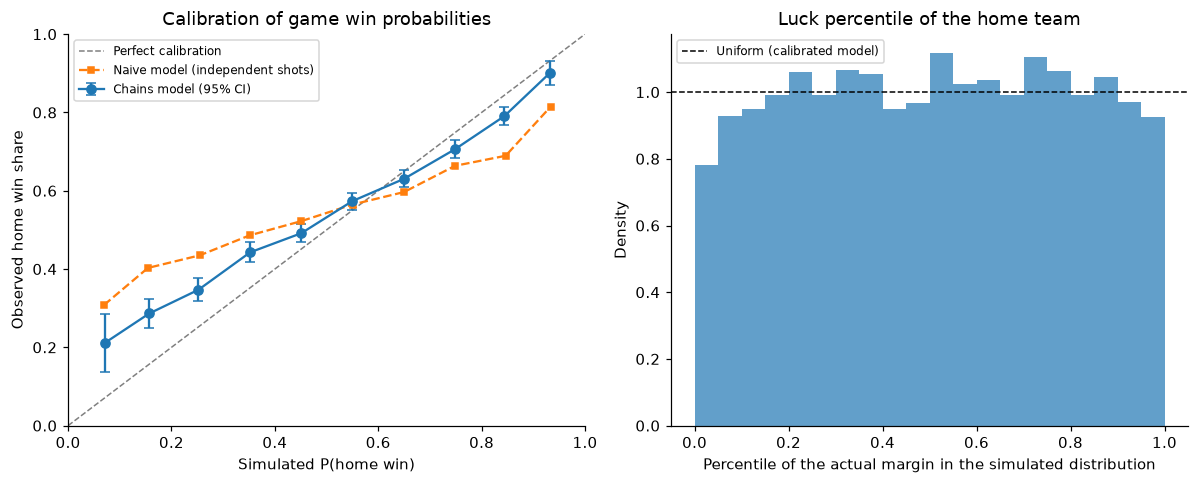

,p,obs,n,se
bin,,,,
"(-0.001, 0.1]",0.072,0.212,118,0.038
"(0.1, 0.2]",0.157,0.286,562,0.019
"(0.2, 0.3]",0.252,0.347,968,0.015
"(0.3, 0.4]",0.352,0.443,1502,0.013
"(0.4, 0.5]",0.451,0.492,1827,0.012
"(0.5, 0.6]",0.550,0.574,1986,0.011
"(0.6, 0.7]",0.650,0.630,1866,0.011
"(0.7, 0.8]",0.748,0.706,1578,0.011
"(0.8, 0.9]",0.844,0.791,1122,0.012


ECE 0.0515, Brier 0.2261
luck percentile: mean 0.507, sd 0.282 (uniform: 0.5, 0.289); chi-square uniformity test (10 bins) chi2 = 51.4, p = 5.91e-08


In [7]:
# calibration of P(home win) and the distribution of the luck percentile
bins = np.linspace(0, 1, 11)
sim["bin"] = pd.cut(sim["p_win_mc"], bins, include_lowest=True)
cal = sim.groupby("bin", observed=True).agg(p=("p_win_mc", "mean"), obs=("home_win", "mean"), n=("home_win", "size"))
cal["se"] = np.sqrt(cal["obs"] * (1 - cal["obs"]) / cal["n"])
ece = float((cal["n"] * (cal["obs"] - cal["p"]).abs()).sum() / cal["n"].sum())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ax = axes[0]
ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="Perfect calibration")
ax.errorbar(cal["p"], cal["obs"], yerr=1.96 * cal["se"], fmt="o-", color="tab:blue", capsize=3,
            label="Chains model (95% CI)")
cal_n = naive.assign(bin=pd.cut(naive["p_win_exact"], bins, include_lowest=True)).groupby("bin", observed=True).agg(
    p=("p_win_exact", "mean"), obs=("home_win", "mean"))
ax.plot(cal_n["p"], cal_n["obs"], "s--", color="tab:orange", ms=4, label="Naive model (independent shots)")
ax.set(xlabel="Simulated P(home win)", ylabel="Observed home win share", xlim=(0, 1), ylim=(0, 1),
       title="Calibration of game win probabilities")
ax.legend(fontsize=8)
ax = axes[1]
ax.hist(sim["luck_pct_mc"], bins=20, range=(0, 1), color="tab:blue", alpha=0.7, density=True)
ax.axhline(1, color="black", ls="--", lw=1, label="Uniform (calibrated model)")
ax.set(xlabel="Percentile of the actual margin in the simulated distribution", ylabel="Density",
       title="Luck percentile of the home team")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_calibration_luck.pdf")
plt.show()
display(cal.round(3))
print(f"ECE {ece:.4f}, Brier {((sim['p_win_mc'] - sim['home_win']) ** 2).mean():.4f}")
counts, _ = np.histogram(sim["luck_pct_mc"], bins=10, range=(0, 1))
chi = stats.chisquare(counts)
print(f"luck percentile: mean {sim['luck_pct_mc'].mean():.3f}, sd {sim['luck_pct_mc'].std():.3f} (uniform: 0.5, 0.289); "
      f"chi-square uniformity test (10 bins) chi2 = {chi.statistic:.1f}, p = {chi.pvalue:.3g}")

**Observations.**
- **The team with the better shots wins 63.3% of games** [62.5%; 64.2%]; **36.7% of games are won by the team whose
  shots were worse**. 32% of games are close by shot quality (0.4 < P < 0.6).
- The expected margin explains **15% of the variance** of game margins (R² 0.152; by season 0.09-0.22). The sd of
  the "luck" part (13.7 points) is almost as large as the sd of margins (14.5). Seen from the shots the teams create,
  a single NBA game is mostly decided by how the shots fall.
- Chains vs naive: favourite wins 63.3% vs 59.1%, R² 0.152 vs 0.074, Brier 0.226 vs 0.250.
- **Calibration**: ECE 0.05. The win probabilities are too extreme at both ends: at P ≈ 0.07 the home team wins 21%,
  at P ≈ 0.93 it wins 90%; in the middle they are close. The model's p does not know who shoots or defends: good teams
  are underrated when they look unlucky, bad ones overrated (see section 6 and the team analysis).
- **Luck percentile**: mean 0.507, sd 0.282 (uniform 0.289); a chi-square test rejects uniformity (p < 10⁻⁷) because of
  the large sample, but the deviation is small: slightly fewer extreme percentiles than a perfect model would give.

## 6. Separating shooter skill from luck

With the average-shooter p, a team of good shooters is "lucky" every night. Here every non-heave shot gets
p' = p + θ / v, where θ is the shooter's shrunk shot making from the **previous season** (Stage 5, previous-season
prior), so no result of the simulated season is used. Players without a previous-season estimate get the mean θ of the
newcomers of the previous season. Adding θ/v to p adds θ points per shot in expectation. 2015-16 has no previous
out-of-sample season, so this comparison uses 2016-17 to 2024-25. Computed exactly (convolution), which section 4 showed
to agree with Monte Carlo.

In [8]:
ps = load_player_shots("../data/processed/oos_predictions.parquet", "../data/processed/shots_features.parquet",
                       "../data/raw/players/positions.parquet")
t = player_table(ps)
est = season_estimates(t, ps.groupby("PLAYER_ID")["POS"].first())
seasons = sorted(est["SEASON"].unique())
theta = []
for prev_s, s in zip(seasons[:-1], seasons[1:]):
    e_prev = est[est["SEASON"] == prev_s]
    newcomers = ~e_prev["PLAYER_ID"].isin(est.loc[est["SEASON"] < prev_s, "PLAYER_ID"]) if prev_s != seasons[0] else e_prev["PLAYER_ID"].notna()
    theta.append(pd.DataFrame({"SEASON": s, "PLAYER_ID": e_prev["PLAYER_ID"], "theta": e_prev["theta"]})
                 .assign(theta_new=e_prev.loc[newcomers, "theta"].mean()))
theta = pd.concat(theta)
new_mean = theta.groupby("SEASON")["theta_new"].first()

sk = shots[shots["SEASON"] != seasons[0]].merge(theta[["SEASON", "PLAYER_ID", "theta"]], on=["SEASON", "PLAYER_ID"], how="left")
sk["theta"] = sk["theta"].fillna(sk["SEASON"].map(new_mean))
sk["p_skill"] = np.where(sk["is_heave"] == 1, sk["p"], np.clip(sk["p"] + sk["theta"] / sk["shot_value"], 0.001, 0.999))
print(f"shots with a previous-season estimate: {sk['PLAYER_ID'].isin(theta['PLAYER_ID']).mean():.3f}; "
      f"mean |p' - p| {np.abs(sk['p_skill'] - sk['p']).mean():.4f}")
sim_skill = run_games(sk, games[games["SEASON"] != seasons[0]], params, p_col="p_skill", mc=False)
base = sim[sim["SEASON"] != seasons[0]]
comp = pd.DataFrame({"average shooter p": game_summary(base, "p_win_exact", "luck_pct_exact"),
                     "p + shooter skill": game_summary(sim_skill, "p_win_exact", "luck_pct_exact")}).T
display(comp.round(4))
both = base[["GAME_ID", "home_win", "p_win_exact"]].merge(sim_skill[["GAME_ID", "p_win_exact"]], on="GAME_ID", suffixes=("", "_skill"))
d = (both["p_win_exact_skill"] - both["home_win"]) ** 2 - (both["p_win_exact"] - both["home_win"]) ** 2
print(f"Brier(skill) - Brier(average): {d.mean():+.5f} {boot_ci(d, np.mean).round(5)}")

shots with a previous-season estimate: 0.990; mean |p' - p| 0.0215


,games,favourite wins,R2 margin,sd margin,sd luck,Brier
average shooter p,10688.0,0.6309,0.1497,14.6521,13.8467,0.2272
p + shooter skill,10688.0,0.6582,0.2012,14.6521,13.3893,0.2152


Brier(skill) - Brier(average): -0.01202 [-0.01329 -0.01079]


**Observations.**
- Adding the shooters' shot making from the previous season (mean change of p 0.02) improves every measure:
  favourite wins 63.1% → 65.8%, R² 0.150 → 0.201, Brier −0.012 [−0.013; −0.011].
- So about a quarter of the explained variance (0.05 of 0.20) comes from **who** takes the shots, not from where and
  when. What the base model calls luck partly is the shooting skill of the players.

## 7. Sensitivity: drawing the free throws

Instead of the real FTM, every free throw attempt is drawn with the team's free throw percentage of the **previous
season** (box scores; 2014-15 is available for 2015-16). Free throw luck is then part of the simulated luck.

In [9]:
box = pd.concat([pd.read_parquet(f) for f in sorted(glob.glob("../data/raw/games/games_*.parquet"))])
ft_season = box.groupby(["TEAM_ID", "SEASON"])[["FTM", "FTA"]].sum()
ft_season["q"] = ft_season["FTM"] / ft_season["FTA"]
order = sorted(box["SEASON"].unique())
prev_of = dict(zip(order[1:], order[:-1]))
qp = ft_season["q"].to_dict()
q = games.set_index("GAME_ID")[["SEASON", "TEAM_ID_home", "TEAM_ID_away"]].copy()
q["q_home"] = [qp[(tid, prev_of[s])] for tid, s in zip(q["TEAM_ID_home"], q["SEASON"])]
q["q_away"] = [qp[(tid, prev_of[s])] for tid, s in zip(q["TEAM_ID_away"], q["SEASON"])]
print(f"team FT% of the previous season: {q['q_home'].min():.3f} to {q['q_home'].max():.3f}")
sim_ft = run_games(shots, games, params, mc=False, ft_prob=q)
comp_ft = pd.DataFrame({"real FTM": game_summary(sim, "p_win_exact", "luck_pct_exact"),
                        "FT drawn": game_summary(sim_ft, "p_win_exact", "luck_pct_exact")}).T
display(comp_ft.round(4))

team FT% of the previous season: 0.668 to 0.839


,games,favourite wins,R2 margin,sd margin,sd luck,Brier
real FTM,11881.0,0.6329,0.1519,14.5201,13.7088,0.2262
FT drawn,11881.0,0.6128,0.1183,14.5201,14.0604,0.2338


**Observations.**
- Drawing free throws with the team's previous-season FT% (66.8-83.9%) adds luck: favourite wins 61.3% instead of
  63.3%, R² 0.118 instead of 0.152. Free throw luck alone moves the explained share of game margins by 3 p.p.
- The main conclusions do not depend on how free throws are treated.

## 8. Teams: expected vs actual wins

Expected wins xW = Σ P(win) over a team's games. Compared with the actual wins W and the **Pythagorean** wins
(win share = PF^14 / (PF^14 + PA^14), the usual NBA exponent, Morey/Oliver), which use the real points.

Is "luck" W − xW really luck? If so, it should **not persist**: luck in the first half of a season should not predict
luck in the second half, and first-half xW should predict second-half wins at least as well as first-half W.

300 team-seasons; sd of W - xW = 9.11 wins, corr(W, xW) = 0.695, corr(W, pythW) = 0.969
sd expected from pure luck given xW: 4.03 wins (rms 4.03)
luckiest and unluckiest team-seasons:


games   W    xW    pf    pa  pythW  luck
SEASON  TEAM                                          
2016-17 SAS      82  61  42.8  8637  8047   59.8  18.2
2017-18 GSW      82  58  39.7  9304  8814   55.8  18.3
2021-22 PHX      82  64  45.0  9416  8801   59.1  19.0
2015-16 SAS      81  66  43.9  8382  7523   66.4  22.1
        GSW      80  72  46.7  9217  8339   64.2  25.3
2023-24 DET      82  14  34.0  9010  9757   20.2 -20.0
2015-16 PHI      81  10  29.0  7889  8697   16.5 -19.0
2020-21 HOU      72  17  35.4  7833  8402   19.6 -18.4
2015-16 LAL      74  14  32.3  7214  7970   14.7 -18.3
2018-19 NYK      82  17  34.5  8575  9330   19.3 -17.5

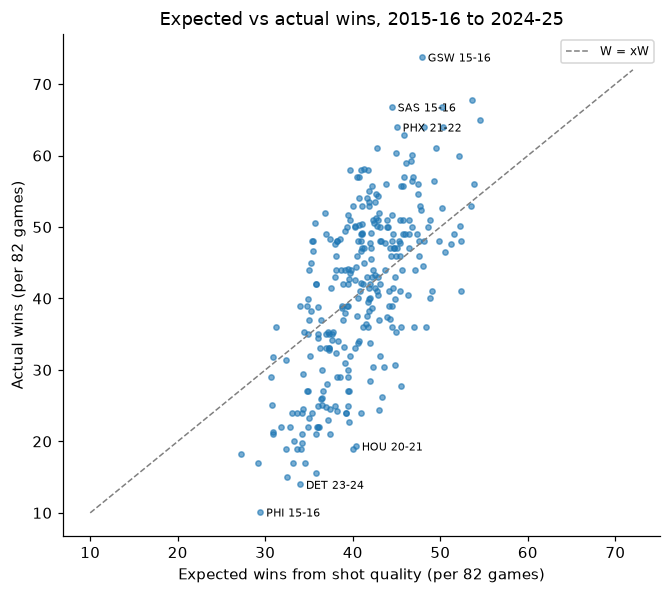

In [10]:
def team_rows(s, p="p_win_mc"):
    h = pd.DataFrame({"SEASON": s["SEASON"], "GAME_ID": s["GAME_ID"], "GAME_DATE": s["GAME_DATE"], "TEAM": s["TEAM_ABBREVIATION_home"],
                      "TEAM_ID": s["TEAM_ID_home"], "w": s["home_win"], "xw": s[p], "pf": s["PTS_home"], "pa": s["PTS_away"]})
    a = pd.DataFrame({"SEASON": s["SEASON"], "GAME_ID": s["GAME_ID"], "GAME_DATE": s["GAME_DATE"], "TEAM": s["TEAM_ABBREVIATION_away"],
                      "TEAM_ID": s["TEAM_ID_away"], "w": 1 - s["home_win"], "xw": 1 - s[p], "pf": s["PTS_away"], "pa": s["PTS_home"]})
    return pd.concat([h, a], ignore_index=True)

def pyth(pf, pa, e=14):
    return 1 / (1 + (np.asarray(pa, float) / np.asarray(pf, float)) ** e)

tr = team_rows(sim)
ts = tr.groupby(["SEASON", "TEAM"]).agg(games=("w", "size"), W=("w", "sum"), xW=("xw", "sum"), pf=("pf", "sum"), pa=("pa", "sum"))
ts["pythW"] = ts["games"] * pyth(ts["pf"], ts["pa"])
ts["luck"] = ts["W"] - ts["xW"]
print(f"{len(ts)} team-seasons; sd of W - xW = {ts['luck'].std():.2f} wins, "
      f"corr(W, xW) = {ts[['W', 'xW']].corr().iloc[0, 1]:.3f}, corr(W, pythW) = {ts[['W', 'pythW']].corr().iloc[0, 1]:.3f}")
# binomial benchmark: if wins were independent Bernoulli(P(win)), sd of W - xW would be sqrt(sum P(1-P))
bench = tr.assign(v=tr["xw"] * (1 - tr["xw"])).groupby(["SEASON", "TEAM"])["v"].sum() ** 0.5
print(f"sd expected from pure luck given xW: {bench.mean():.2f} wins (rms {np.sqrt((bench ** 2).mean()):.2f})")
print("luckiest and unluckiest team-seasons:")
display(pd.concat([ts.sort_values("luck").tail(5), ts.sort_values("luck").head(5)]).round(1))

fig, ax = plt.subplots(figsize=(6.2, 5.5))
ax.scatter(ts["xW"] / ts["games"] * 82, ts["W"] / ts["games"] * 82, s=12, alpha=0.6, color="tab:blue")
ax.plot([10, 72], [10, 72], color="grey", ls="--", lw=1, label="W = xW")
for (season, team), r in pd.concat([ts.sort_values("luck").tail(3), ts.sort_values("luck").head(3)]).iterrows():
    ax.annotate(f"{team} {season[2:]}", (r["xW"] / r["games"] * 82, r["W"] / r["games"] * 82), fontsize=7,
                xytext=(4, -3), textcoords="offset points")
ax.set(xlabel="Expected wins from shot quality (per 82 games)", ylabel="Actual wins (per 82 games)",
       title="Expected vs actual wins, 2015-16 to 2024-25")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_team_wins.pdf")
plt.show()

In [11]:
# persistence: split each team-season at the median game date of the season
mid = tr.groupby("SEASON")["GAME_DATE"].transform("median")
tr["half"] = np.where(tr["GAME_DATE"] <= mid, 1, 2)
hs = tr.groupby(["SEASON", "TEAM", "half"]).agg(g=("w", "size"), w=("w", "mean"), xw=("xw", "mean"), pf=("pf", "sum"), pa=("pa", "sum")).unstack()
hs = pd.DataFrame({"w1": hs[("w", 1)], "xw1": hs[("xw", 1)], "pyth1": pyth(hs[("pf", 1)], hs[("pa", 1)]),
                   "w2": hs[("w", 2)], "xw2": hs[("xw", 2)], "g2": hs[("g", 2)]}).dropna()
hs["luck1"], hs["luck2"] = hs["w1"] - hs["xw1"], hs["w2"] - hs["xw2"]
r = stats.pearsonr(hs["luck1"], hs["luck2"])
print(f"corr(luck first half, luck second half) = {r.statistic:.3f}, 95% CI {np.round(r.confidence_interval(), 3)}, p = {r.pvalue:.3f}")
r = stats.pearsonr(hs["xw1"], hs["xw2"])
print(f"corr(xW% first half, xW% second half) = {r.statistic:.3f}")
idx = np.arange(len(hs))
pred = {"first-half W%": hs["w1"], "first-half xW%": hs["xw1"], "first-half Pythagorean": hs["pyth1"], "0.5": 0.5 + 0 * hs["w1"]}
rmse = {k: np.sqrt(np.mean((v - hs["w2"]) ** 2)) for k, v in pred.items()}
rng = np.random.default_rng(0)
bs = rng.integers(len(hs), size=(1000, len(hs)))
e_w = ((hs["w1"] - hs["w2"]) ** 2).to_numpy()
rows = []
for k, v in pred.items():
    e_k = ((v - hs["w2"]) ** 2).to_numpy()
    dd = e_k[bs].mean(axis=1) - e_w[bs].mean(axis=1)
    rows.append({"predictor": k, "RMSE": rmse[k], "MSE - MSE(W%)": (e_k - e_w).mean(), "ci_low": np.quantile(dd, 0.025), "ci_high": np.quantile(dd, 0.975)})
display(pd.DataFrame(rows).set_index("predictor").round(5))

corr(luck first half, luck second half) = 0.647, 95% CI [0.576 0.709], p = 0.000
corr(xW% first half, xW% second half) = 0.648


,RMSE,MSE - MSE(W%),ci_low,ci_high
predictor,,,,
first-half W%,0.12128,0.00000,0.00000,0.00000
first-half xW%,0.14033,0.00498,0.00222,0.00803
first-half Pythagorean,0.11602,-0.00125,-0.00259,0.00021
0.5,0.16359,0.01205,0.00843,0.01615


In [12]:
# where does the persistent part of "luck" come from? Team shot making in attack and in defence
# (points per shot above xPTS of a team's own shots and of its opponents' shots, centred per season), half-season split
x = shots.merge(games[["GAME_ID", "GAME_DATE", "TEAM_ID_home", "TEAM_ID_away"]], on="GAME_ID")
x["opp"] = np.where(x["side"] == "home", x["TEAM_ID_away"], x["TEAM_ID_home"])
x["r"] = x["shot_value"] * (x["y"] - x["p"])
x["r"] -= x.groupby("SEASON")["r"].transform("mean")
x["half"] = np.where(x["GAME_DATE"] <= x.groupby("SEASON")["GAME_DATE"].transform("median"), 1, 2)
for name, by in [("attack (own shots)", "TEAM_ID"), ("defence (opponents' shots)", "opp")]:
    h = x.groupby(["SEASON", by, "half"])["r"].mean().unstack()
    r = stats.pearsonr(h[1], h[2])
    print(f"team shot making in {name}: sd {h[1].std():.3f} points/shot, corr between halves {r.statistic:.3f}, "
          f"95% CI {np.round(r.confidence_interval(), 3)}")

# the same persistence test with the skill-adjusted variant (2016-17 to 2024-25)
tr_s = team_rows(sim_skill, "p_win_exact")
tr_s["half"] = np.where(tr_s["GAME_DATE"] <= tr_s.groupby("SEASON")["GAME_DATE"].transform("median"), 1, 2)
hk = tr_s.groupby(["SEASON", "TEAM", "half"]).agg(w=("w", "mean"), xw=("xw", "mean")).unstack()
lk1, lk2 = hk[("w", 1)] - hk[("xw", 1)], hk[("w", 2)] - hk[("xw", 2)]
r = stats.pearsonr(lk1, lk2)
ts_s = tr_s.groupby(["SEASON", "TEAM"]).agg(W=("w", "sum"), xW=("xw", "sum"))
print(f"skill-adjusted: sd of W - xW {(ts_s['W'] - ts_s['xW']).std():.2f} wins, corr(W, xW) {ts_s[['W', 'xW']].corr().iloc[0, 1]:.3f}, "
      f"corr(luck first half, second half) {r.statistic:.3f}, 95% CI {np.round(r.confidence_interval(), 3)}")

team shot making in attack (own shots): sd 0.039 points/shot, corr between halves 0.643, 95% CI [0.572 0.705]
team shot making in defence (opponents' shots): sd 0.032 points/shot, corr between halves 0.508, 95% CI [0.419 0.587]
skill-adjusted: sd of W - xW 7.30 wins, corr(W, xW) 0.825, corr(luck first half, second half) 0.526, 95% CI [0.434 0.607]


**Observations.**
- Over a season, expected wins xW and actual wins W correlate 0.70, but the sd of W − xW is **9.1 wins** while pure
  luck (independent games with P(win)) would give only **4.0 wins**. Most of W − xW is therefore **not** luck.
- The largest positive gaps are great teams: 2015-16 Golden State (72 wins, xW 46.7, +25), 2015-16 San Antonio,
  2021-22 Phoenix, 2017-18 Golden State, 2016-17 San Antonio. The largest negative gaps are bad teams: 2023-24 Detroit
  (14 wins, xW 34), 2015-16 Philadelphia, 2020-21 Houston.
- **"Luck" persists**: corr(W − xW in the first half, in the second half) = 0.65 [0.58; 0.71]. Real luck could not do that.
  First-half xW% predicts second-half W% worse than first-half W% (MSE +0.005 [0.002; 0.008]), and the Pythagorean
  formula from real points is the best predictor (−0.0013 [−0.0026; 0.0002] vs W%).
- The persistent part is team shot making in **attack and in defence** (last cell above): the model knows the shot location and
  context, but not that Curry is shooting or that a good defender is contesting.

**Observations.**
- Team shot making in attack has sd 0.039 points per shot and correlates 0.64 between the halves of a season; in defence
  (points above xPTS allowed) sd 0.032, correlation 0.51. Both are stable team qualities, not luck.
- With player shot making in p (2016-17 to 2024-25) the sd of W − xW falls from 9.1 to 7.3 wins, corr(W, xW) rises
  from 0.70 to 0.83, and the persistence of W − xW drops from 0.65 to 0.53 [0.43; 0.61]. It does not vanish, because
  defence and the remaining skill are still missing.
- **Conclusion for RQ3**: in one game, field goal luck is large (sd about 14 points; the team with the better shots wins
  only 63%). Over a season, luck in this narrow sense is about ±4 wins; the much larger gap between shot quality and
  wins (±9 wins) is skill in making and preventing shots.

## 9. Hold-out season 2025-26 (run once)

The same simulation with the predictions of `09_holdout` (model trained on 2023-24 and 2024-25). Shooter skill for the
skill-adjusted variant comes from the 2024-25 estimates.

In [13]:
hshots, hgames, hbad = load_games(P + "holdout_predictions.parquet", P + "shots_features.parquet", P + "shots_context.parquet",
                                  "../data/raw/games")
params.loc["2025-26"] = pp.loc["2024-25"]
print(f"2025-26: {len(hgames)} games, dropped {hbad}")
hsim = run_games(hshots, hgames, params, n_sims=N_SIMS, seed=1)
hsim.to_parquet("../data/processed/game_simulations_holdout.parquet")
hl = est[est["SEASON"] == "2024-25"]
newc = ~hl["PLAYER_ID"].isin(est.loc[est["SEASON"] < "2024-25", "PLAYER_ID"])
hshots = hshots.merge(hl[["PLAYER_ID", "theta"]], on="PLAYER_ID", how="left")
hshots["theta"] = hshots["theta"].fillna(hl.loc[newc, "theta"].mean())
hshots["p_skill"] = np.where(hshots["is_heave"] == 1, hshots["p"], np.clip(hshots["p"] + hshots["theta"] / hshots["shot_value"], 0.001, 0.999))
hsim_skill = run_games(hshots, hgames, params, p_col="p_skill", mc=False)
hres = pd.DataFrame({"2025-26 average shooter p": game_summary(hsim),
                     "2025-26 p + shooter skill": game_summary(hsim_skill, "p_win_exact", "luck_pct_exact"),
                     "2015-16 to 2024-25": game_summary(sim)}).T
display(hres.round(4))
cal_h = hsim.assign(bin=pd.cut(hsim["p_win_mc"], bins, include_lowest=True)).groupby("bin", observed=True).agg(
    p=("p_win_mc", "mean"), obs=("home_win", "mean"), n=("home_win", "size"))
print(f"ECE 2025-26: {float((cal_h['n'] * (cal_h['obs'] - cal_h['p']).abs()).sum() / cal_h['n'].sum()):.4f}")
fav_h = np.where(hsim["p_win_mc"] > 0.5, hsim["home_win"], 1 - hsim["home_win"])
print(f"favourite wins {fav_h.mean():.3f} {boot_ci(fav_h, np.mean).round(3)}")
htr = team_rows(hsim)
hts = htr.groupby("TEAM").agg(games=("w", "size"), W=("w", "sum"), xW=("xw", "sum"))
hts["luck"] = hts["W"] - hts["xW"]
display(pd.concat([hts.sort_values("luck").tail(3), hts.sort_values("luck").head(3)]).round(1))

2025-26: 1225 games, dropped 0


,games,favourite wins,R2 margin,sd margin,sd luck,Brier
2025-26 average shooter p,1225.0,0.6971,0.3298,16.4323,13.4640,0.1966
2025-26 p + shooter skill,1225.0,0.7069,0.3755,16.4323,13.0045,0.1867
2015-16 to 2024-25,11881.0,0.6334,0.1519,14.5201,13.7088,0.2261


ECE 2025-26: 0.0348
favourite wins 0.697 [0.673 0.722]


,games,W,xW,luck
TEAM,,,,
BOS,82,56,44.0,12.0
LAL,82,53,39.6,13.4
DEN,82,54,38.8,15.2
BKN,82,20,35.1,-15.1
NOP,82,26,40.6,-14.6
IND,82,19,32.7,-13.7


**Observations.**
- 2025-26 (1,225 games, none dropped): favourite by shot quality wins **69.7%** [67.3%; 72.2%], R² 0.33, Brier 0.197,
  ECE 0.035; with player skill 70.7%, R² 0.38, Brier 0.187. Both clearly better than in 2015-2025.
- A probable reason is the play-by-play format: 2025-26 uses the v3 feed, which contains offensive rebounds missing in
  the v2 archive (Stage 4), so chains are found more completely (putback share 11.2% vs about 10%). The naive-vs-chains
  analysis shows that chains are what matters most; this is a hypothesis, not tested here.
- The conclusions hold: shot quality decides a majority but far from all games, and adding shooter skill helps.

## 10. Summary

- **Method.** Retrospective Monte Carlo with the real shots and free throws, only field goal results drawn from the
  out-of-sample p. Shots are grouped into chains (shot + putbacks), otherwise missing shots create expected points
  (naive model: R² 0.07, chains: 0.15). Monte Carlo (10,000 runs) agrees with the exact distribution (convolution) within
  its standard error; the normal approximation is almost exact; antithetic variates save about a third of the variance.
- **One game.** The team with the better shots wins 63% of games; luck in making shots has sd about 14 points per game
  and explains most of the variance of game margins (shot quality 15%, 20% with player skill).
- **Calibration.** P(win) from shot quality is too extreme at the ends (ECE 0.05) because the model ignores who
  shoots and who defends.
- **Season.** W − xW has sd 9 wins, pure luck 4 wins; the gap persists between halves (r 0.65), so it is mostly team
  shot making in attack (r 0.64) and defence (r 0.51), not luck.
- **Hold-out 2025-26.** Same conclusions, stronger relation (favourite 70%, R² 0.33).
- **Limits.** Shot counts and turnovers are fixed; generic putbacks; no defender information; FT taken as observed.

Figures: `06_example_game.pdf`, `06_convergence.pdf`, `06_calibration_luck.pdf`, `06_team_wins.pdf`.